In [3]:
from pathlib import Path
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.metrics import adjusted_rand_score

project_root = Path.cwd()
if project_root.name == "notebooks":
    project_root = project_root.parent

interim_dir = project_root / "data" / "interim"
processed_dir = project_root / "data" / "processed"
models_dir = project_root / "models" / "phase2"
figures_dir = project_root / "figures" / "phase2"

ASPECT_NAMES = {
    0: "rc_car_performance",
    1: "value_price_shipping",
    2: "drone_flight_camera",
    3: "battery_charging",
    4: "gift_kids_engagement"
}

df_sentences_all = pd.read_parquet(interim_dir / "train_sentences_extracted.parquet", engine="fastparquet")
df_cluster_20k = pd.read_parquet(interim_dir / "train_sentences_clustered_20k.parquet", engine="fastparquet")
X_embeddings_20k = np.load(interim_dir / "train_embeddings_20k.npy")

reducer_5d = joblib.load(models_dir / "umap_5d_reducer.joblib")
kmeans_ref = joblib.load(models_dir / "kmeans_k5.joblib")

X_umap_5d = reducer_5d.transform(X_embeddings_20k)
ref_labels = df_cluster_20k["cluster_id"].values
OPTIMAL_K = 5

print(f"بارگذاری موفق: {len(df_cluster_20k):,} جمله خوشه‌بندی‌شده | {len(df_sentences_all):,} کل جملات استخراج‌شده")



بارگذاری موفق: 20,000 جمله خوشه‌بندی‌شده | 139,520 کل جملات استخراج‌شده


## ۱. تسک ۵: ارزیابی پایداری خوشه‌ها (Seed & Subsampling Stability)



پایداری با تغییر Seed (8 اجرا) -> میانگین ARI: 0.9682 ± 0.0182
پایداری با تغییر زیرنمونه 80% (8 اجرا) -> میانگین ARI: 0.9710 ± 0.0230


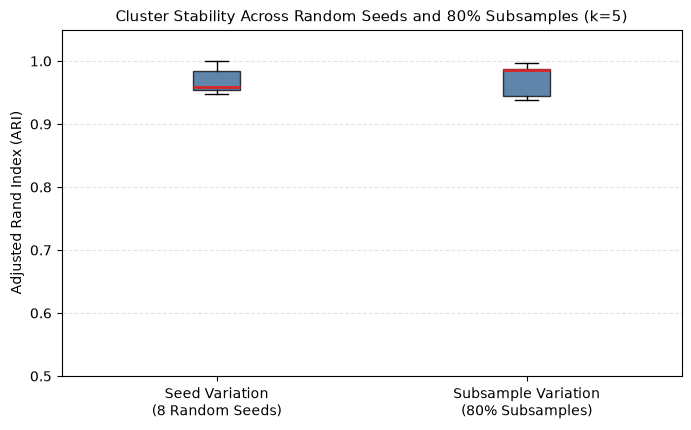

نمودار پایداری ذخیره شد در: d:\University\Semaster-7\Data Analysis\Project\DataAnalysis-Project-Fall2026\figures\phase2\cluster_stability_ari.png


In [4]:
seeds = [10, 20, 30, 40, 50, 99, 123, 2024]
seed_aris = []
subsample_aris = []

for s in seeds:
    km_temp = KMeans(n_clusters=OPTIMAL_K, random_state=s, n_init=10)
    labels_temp = km_temp.fit_predict(X_umap_5d)
    seed_aris.append(adjusted_rand_score(ref_labels, labels_temp))

n_samples = len(X_umap_5d)
sub_size = int(0.8 * n_samples)

for s in seeds:
    rng = np.random.RandomState(s)
    idx = rng.choice(n_samples, size=sub_size, replace=False)
    km_sub = KMeans(n_clusters=OPTIMAL_K, random_state=42, n_init=10)
    labels_sub = km_sub.fit_predict(X_umap_5d[idx])
    subsample_aris.append(adjusted_rand_score(ref_labels[idx], labels_sub))

print(f"پایداری با تغییر Seed (8 اجرا) -> میانگین ARI: {np.mean(seed_aris):.4f} ± {np.std(seed_aris):.4f}")
print(f"پایداری با تغییر زیرنمونه 80% (8 اجرا) -> میانگین ARI: {np.mean(subsample_aris):.4f} ± {np.std(subsample_aris):.4f}")

plt.figure(figsize=(8, 4.5))
plt.boxplot(
    [seed_aris, subsample_aris],
    tick_labels=["Seed Variation\n(8 Random Seeds)", "Subsample Variation\n(80% Subsamples)"],
    patch_artist=True,
    boxprops=dict(facecolor="#2b5c8f", alpha=0.75),
    medianprops=dict(color="#d62728", linewidth=2)
)
plt.ylim(0.5, 1.05)
plt.ylabel("Adjusted Rand Index (ARI)", fontsize=10)
plt.title("Cluster Stability Across Random Seeds and 80% Subsamples (k=5)", fontsize=11)
plt.grid(axis="y", linestyle="--", alpha=0.35)

stability_plot_path = figures_dir / "cluster_stability_ari.png"
plt.savefig(stability_plot_path, dpi=300, bbox_inches="tight")
plt.show()
print(f"نمودار پایداری ذخیره شد در: {stability_plot_path}")



## ۲. تسک ۴: مهندسی ویژگی‌های سطح نقد (تجمیع جنبه‌ها + ویژگی‌های ساخت‌یافته)



In [5]:
df_cluster_20k["aspect_name"] = df_cluster_20k["cluster_id"].map(ASPECT_NAMES)

aspect_counts = pd.crosstab(
    index=[df_cluster_20k["parent_asin"], df_cluster_20k["timestamp"]],
    columns=df_cluster_20k["aspect_name"]
)

aspect_ratios = aspect_counts.div(aspect_counts.sum(axis=1), axis=0).add_prefix("aspect_ratio_")
aspect_counts = aspect_counts.add_prefix("aspect_count_")

text_struct_feats = df_cluster_20k.groupby(["parent_asin", "timestamp"]).agg(
    sampled_sentence_count=("sentence_id", "count"),
    avg_sentence_word_count=("sentence_word_count", "mean"),
    max_sentence_word_count=("sentence_word_count", "max"),
    rating=("rating", "first")
)

df_review_aspects = pd.concat([text_struct_feats, aspect_ratios, aspect_counts], axis=1).reset_index()

reviews_raw = pd.read_parquet(processed_dir / "reviews_rc.parquet", engine="fastparquet")
meta_raw = pd.read_parquet(processed_dir / "meta_rc.parquet", engine="fastparquet")

reviews_raw["review_dt"] = pd.to_datetime(reviews_raw["timestamp"], unit="ms")
reviews_train = reviews_raw[(reviews_raw["review_dt"].dt.year >= 2015) & (reviews_raw["review_dt"].dt.year <= 2020)].copy()

struct_cols = ["parent_asin", "timestamp", "helpful_vote", "verified_purchase", "n_images", "title", "text"]
available_struct_cols = [c for c in struct_cols if c in reviews_train.columns]
reviews_sub = reviews_train[available_struct_cols].drop_duplicates(subset=["parent_asin", "timestamp"])

df_features = pd.merge(df_review_aspects, reviews_sub, on=["parent_asin", "timestamp"], how="inner")

df_features["review_char_len"] = df_features["text"].fillna("").str.len()
df_features["title_char_len"] = df_features["title"].fillna("").str.len()
df_features["has_image"] = (df_features["n_images"].fillna(0) > 0).astype(int)
df_features["verified_purchase_int"] = df_features["verified_purchase"].fillna(False).astype(int)

dt_series = pd.to_datetime(df_features["timestamp"], unit="ms")
df_features["review_year"] = dt_series.dt.year
df_features["review_month"] = dt_series.dt.month
df_features["is_q4_holiday"] = dt_series.dt.month.isin([10, 11, 12]).astype(int)

meta_cols = [c for c in ["parent_asin", "price", "average_rating", "rating_number"] if c in meta_raw.columns]
if len(meta_cols) > 1:
    meta_sub = meta_raw[meta_cols].drop_duplicates(subset=["parent_asin"])
    df_features = pd.merge(df_features, meta_sub, on="parent_asin", how="left")
    if "price" in df_features.columns:
        df_features["price_numeric"] = pd.to_numeric(df_features["price"], errors="coerce")
        df_features["price_is_missing"] = df_features["price_numeric"].isna().astype(int)
        df_features["price_imputed"] = df_features["price_numeric"].fillna(df_features["price_numeric"].median())

drop_raw_text = [c for c in ["title", "text", "price", "verified_purchase"] if c in df_features.columns]
df_features_final = df_features.drop(columns=drop_raw_text)

print(f"ابعاد دیتاست نهایی مهندسی‌شده (سطح نقد): {df_features_final.shape}")
display(df_features_final.head(5))



ابعاد دیتاست نهایی مهندسی‌شده (سطح نقد): (14792, 30)


,parent_asin,timestamp,sampled_sentence_count,avg_sentence_word_count,max_sentence_word_count,rating,aspect_ratio_battery_charging,aspect_ratio_drone_flight_camera,aspect_ratio_gift_kids_engagement,aspect_ratio_rc_car_performance,...,has_image,verified_purchase_int,review_year,review_month,is_q4_holiday,average_rating,rating_number,price_numeric,price_is_missing,price_imputed
0,0911295895,1427049393000,1,16.000000,16,2.0,0.000000,1.0,0.0,0.0,...,0,1,2015,3,0,2.0,1,NaN,1,34.985
1,8499000606,1421605429000,2,7.000000,10,5.0,0.000000,0.0,0.0,1.0,...,0,1,2015,1,0,4.2,5962,24.98,0,24.980
2,8499000606,1424996518000,3,16.333333,23,5.0,0.666667,0.0,0.0,0.0,...,0,1,2015,2,0,4.2,5962,24.98,0,24.980
3,8499000606,1426003702000,1,4.000000,4,4.0,0.000000,0.0,0.0,0.0,...,0,1,2015,3,0,4.2,5962,24.98,0,24.980
4,8499000606,1429898102000,1,7.000000,7,5.0,0.000000,0.0,0.0,0.0,...,0,1,2015,4,0,4.2,5962,24.98,0,24.980


## ۳. ذخیره دیتاست نهایی فاز دوم برای ورود به فاز سوم



In [6]:
final_features_path = processed_dir / "phase2_train_engineered_features.parquet"
df_features_final.to_parquet(final_features_path, engine="fastparquet", index=False)

feature_list_path = interim_dir / "phase2_feature_catalog.csv"
pd.DataFrame({
    "feature_name": df_features_final.columns,
    "dtype": df_features_final.dtypes.astype(str),
    "missing_count": df_features_final.isna().sum().values
}).to_csv(feature_list_path, index=False)

print(f"دیتاست نهایی فاز دوم ذخیره شد در: {final_features_path}")
print(f"کاتالوگ ویژگی‌ها ذخیره شد در: {feature_list_path}")


دیتاست نهایی فاز دوم ذخیره شد در: d:\University\Semaster-7\Data Analysis\Project\DataAnalysis-Project-Fall2026\data\processed\phase2_train_engineered_features.parquet
کاتالوگ ویژگی‌ها ذخیره شد در: d:\University\Semaster-7\Data Analysis\Project\DataAnalysis-Project-Fall2026\data\interim\phase2_feature_catalog.csv
